# Ocultamiento y recuperación de mensajes de audio mediante permutación espectral

**Análisis de Señales — Universidad Militar Nueva Granada**
**Integrantes:** Andrés Felipe David · María Camila Rojas

In [1]:
import os, sys, glob

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    carpeta = '/content/drive/MyDrive/proyecto-permutacion-espectral'
    if not os.path.isdir(os.path.join(carpeta, 'audios_grabados')):
        carpeta = os.path.dirname(glob.glob('/content/drive/MyDrive/**/audios_grabados', recursive=True)[0])
    os.chdir(carpeta)
print(os.getcwd())

/tmp/claude-0/entrega/proyecto-permutacion-espectral


In [2]:
import subprocess, tempfile
import numpy as np
import matplotlib.pyplot as plt
from math import gcd
from pathlib import Path
from scipy.io.wavfile import read, write
from scipy.fft import rfft, irfft, rfftfreq
from scipy.signal import resample_poly
from IPython.display import Audio, display

DIR_GRABADOS, DIR_ORIGINALES = Path('audios_grabados'), Path('audios_originales')
DIR_ENCODED, DIR_CLAVES = Path('encoded'), Path('claves')
DIR_RECUPERADOS, DIR_FIGURAS = Path('recuperados'), Path('figuras')
for carpeta in (DIR_ORIGINALES, DIR_ENCODED, DIR_CLAVES, DIR_RECUPERADOS, DIR_FIGURAS):
    carpeta.mkdir(exist_ok=True)

NOMBRES = ['target', 'secret1', 'secret2', 'secret3', 'secret4', 'secret5']
AZUL, NARANJA, VERDE = 'royalblue', 'darkorange', 'seagreen'

## 0. Preparación de los audios

In [3]:
def leer_audio(ruta):
    fs, muestras = read(ruta)
    if np.issubdtype(muestras.dtype, np.integer):
        return fs, muestras.astype(np.float64) / 2.0 ** (8 * muestras.dtype.itemsize - 1)
    return fs, muestras.astype(np.float64)


def cargar_grabacion(ruta, fs_destino=None):
    if ruta.suffix.lower() == '.wav':
        fs, x = leer_audio(ruta)
    else:
        with tempfile.TemporaryDirectory() as tmp:
            destino = Path(tmp) / 'audio.wav'
            subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', str(ruta), str(destino)], check=True)
            fs, x = leer_audio(destino)
    if x.ndim == 2:
        x = x.mean(axis=1)
    if fs_destino and fs != fs_destino:
        g = gcd(fs_destino, fs)
        x, fs = resample_poly(x, fs_destino // g, fs // g), fs_destino
    return fs, x


fs, senales = None, {}
for nombre in NOMBRES:
    fs, senales[nombre] = cargar_grabacion(sorted(DIR_GRABADOS.glob(nombre + '.*'))[0], fs)

N = max(len(x) for x in senales.values())
for nombre, x in senales.items():
    x = np.pad(x, (0, N - len(x)))
    write(DIR_ORIGINALES / f'{nombre}.wav', fs, np.clip(np.round(x * 32768), -32768, 32767).astype(np.int16))

print(f'fs = {fs} Hz   N = {N} muestras   duración = {N / fs:.2f} s')

fs = 48000 Hz   N = 547200 muestras   duración = 11.40 s


## Parte I — Imitation

### 1. Carga y exploración temporal

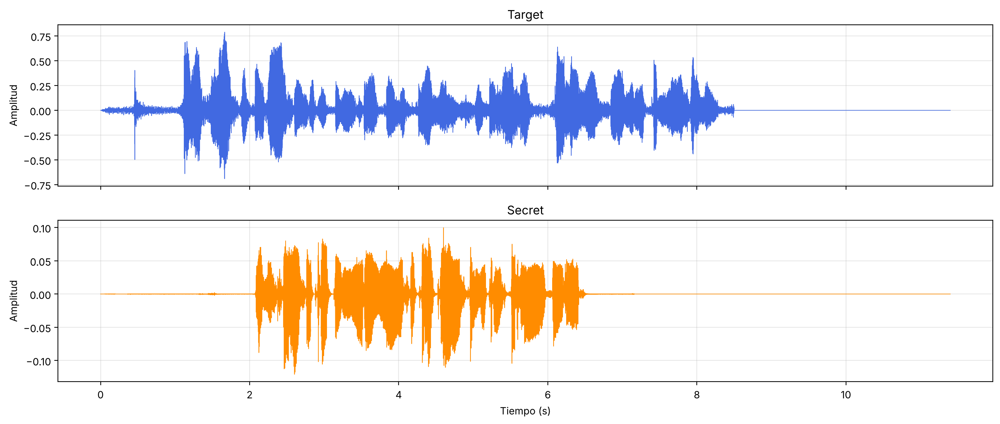

In [4]:
fs_t, target = leer_audio(DIR_ORIGINALES / 'target.wav')
fs_s, secret = leer_audio(DIR_ORIGINALES / 'secret1.wav')
assert fs_t == fs_s and len(target) == len(secret)
fs, N = fs_t, len(target)
tiempo = np.arange(N) / fs

fig, ejes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
ejes[0].plot(tiempo, target, color=AZUL, linewidth=0.6)
ejes[0].set_title('Target')
ejes[1].plot(tiempo, secret, color=NARANJA, linewidth=0.6)
ejes[1].set_title('Secret')
ejes[1].set_xlabel('Tiempo (s)')
for eje in ejes:
    eje.set_ylabel('Amplitud')
    eje.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(DIR_FIGURAS / 'tiempo_target_secret1.png', dpi=110)
plt.show()

display(Audio(target, rate=fs), Audio(secret, rate=fs))

### 2. Análisis espectral

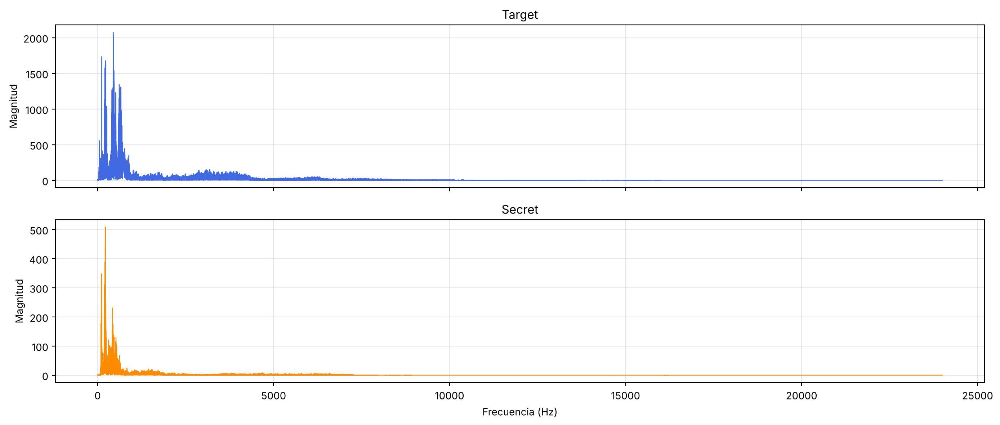

In [5]:
T = rfft(target)
S = rfft(secret)
frecuencias = rfftfreq(N, d=1 / fs)
M = len(S)


def graficar_espectros(lista, archivo):
    fig, ejes = plt.subplots(len(lista), 1, figsize=(14, 3 * len(lista)), sharex=True)
    for eje, (titulo, X, color) in zip(ejes, lista):
        eje.plot(frecuencias, np.abs(X), color=color, linewidth=0.8)
        eje.set_title(titulo)
        eje.set_ylabel('Magnitud')
        eje.grid(alpha=0.3)
    ejes[-1].set_xlabel('Frecuencia (Hz)')
    fig.tight_layout()
    fig.savefig(archivo, dpi=110)
    plt.show()


graficar_espectros([('Target', T, AZUL), ('Secret', S, NARANJA)], DIR_FIGURAS / 'espectro_target_secret1.png')

### 3. Reorganización de coeficientes complejos y clave de permutación

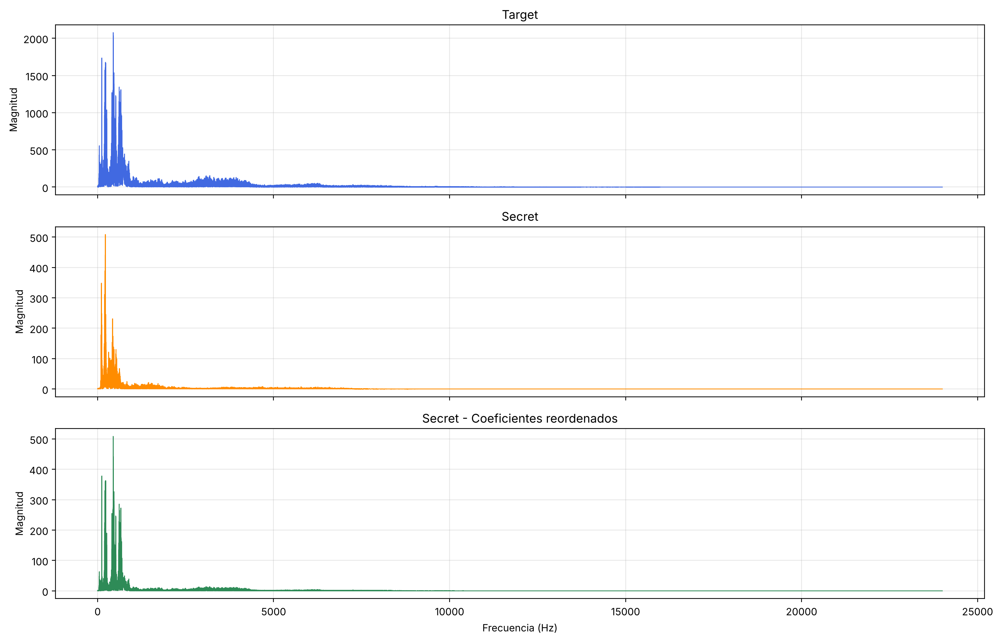

In [6]:
def construir_clave(S, T, N):
    M = len(S)
    P = np.arange(1, M - 1) if N % 2 == 0 else np.arange(1, M)
    I1 = np.argsort(np.abs(S[P]))
    I2 = np.argsort(np.abs(T[P]))
    K = np.arange(M)
    K[P[I2]] = P[I1]
    return K


K = construir_clave(S, T, N)
E = S[K]

graficar_espectros([('Target', T, AZUL), ('Secret', S, NARANJA),
                    ('Secret - Coeficientes reordenados', E, VERDE)],
                   DIR_FIGURAS / 'espectro_ordenado_secret1.png')

### 4. Generación del audio codificado

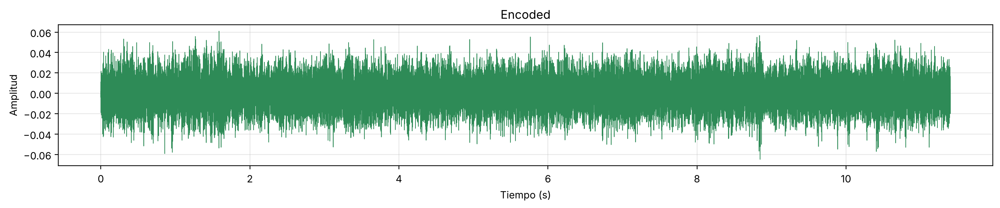

In [7]:
def guardar_resultados(encoded, K, etiqueta):
    write(DIR_ENCODED / f'encoded_{etiqueta}.wav', fs, encoded.astype(np.float32))
    np.savetxt(DIR_CLAVES / f'FFT_key_{etiqueta}.csv', K, fmt='%d', header='K', comments='')


encoded = irfft(E, n=N)
guardar_resultados(encoded, K, 'secret1')

fig, eje = plt.subplots(figsize=(14, 3))
eje.plot(tiempo, encoded, color=VERDE, linewidth=0.6)
eje.set_title('Encoded')
eje.set_xlabel('Tiempo (s)')
eje.set_ylabel('Amplitud')
eje.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(DIR_FIGURAS / 'encoded_secret1.png', dpi=110)
plt.show()

display(Audio(encoded, rate=fs))

### 5. Repetición con los cinco secretos

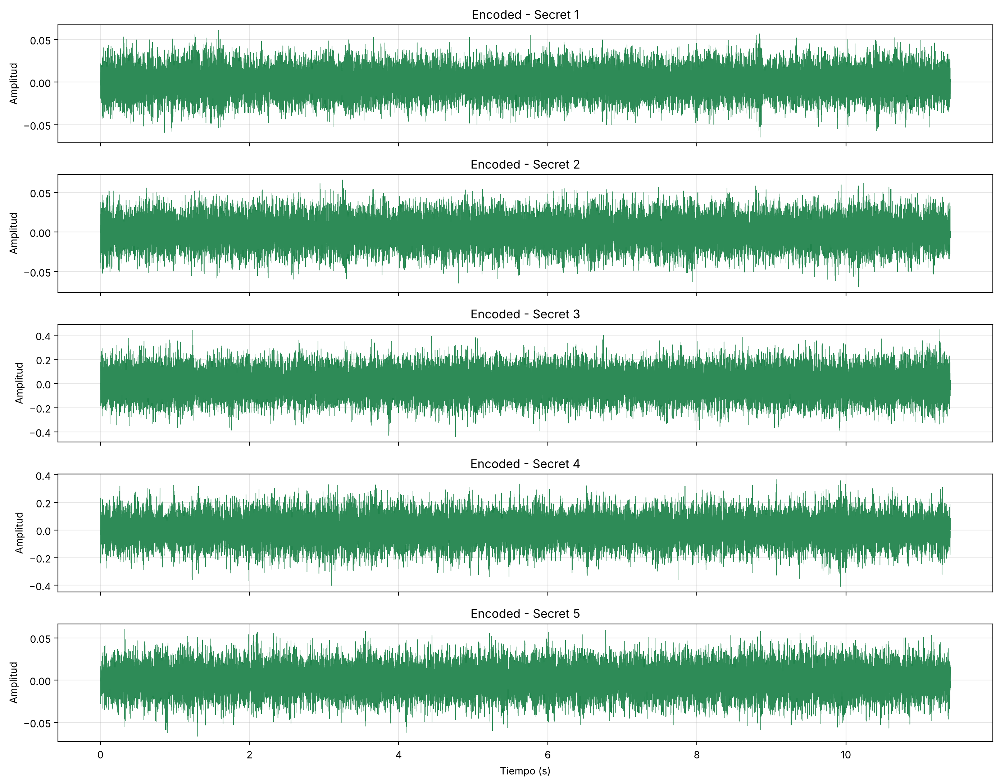

['encoded_secret1.wav', 'encoded_secret2.wav', 'encoded_secret3.wav', 'encoded_secret4.wav', 'encoded_secret5.wav']
['FFT_key_secret1.csv', 'FFT_key_secret2.csv', 'FFT_key_secret3.csv', 'FFT_key_secret4.csv', 'FFT_key_secret5.csv']


In [8]:
def imitation(etiqueta):
    _, secret = leer_audio(DIR_ORIGINALES / f'{etiqueta}.wav')
    S = rfft(secret)
    K = construir_clave(S, T, N)
    E = S[K]
    encoded = irfft(E, n=N)
    guardar_resultados(encoded, K, etiqueta)
    return encoded


fig, ejes = plt.subplots(5, 1, figsize=(14, 11), sharex=True)
for i, eje in enumerate(ejes, start=1):
    enc = imitation(f'secret{i}')
    eje.plot(tiempo, enc, color=VERDE, linewidth=0.5)
    eje.set_title(f'Encoded - Secret {i}')
    eje.set_ylabel('Amplitud')
    eje.grid(alpha=0.3)
ejes[-1].set_xlabel('Tiempo (s)')
fig.tight_layout()
fig.savefig(DIR_FIGURAS / 'encoded_cinco_secretos.png', dpi=110)
plt.show()

print(sorted(p.name for p in DIR_ENCODED.glob('*.wav')))
print(sorted(p.name for p in DIR_CLAVES.glob('*.csv')))

## Parte II — Reverse (código suministrado por la profesora)

In [9]:
for i in range(1, 6):
    archivo_encoded = f'encoded/encoded_secret{i}.wav'
    archivo_clave = f'claves/FFT_key_secret{i}.csv'
    archivo_recuperado = f'recuperados/recovered_secret{i}.wav'

    # 1. CARGAR AUDIO CODIFICADO Y CLAVE
    fs, encoded = read(archivo_encoded)
    key = np.loadtxt(archivo_clave, delimiter=',', skiprows=1, dtype=int)

    # 2. TRANSFORMADA DE FOURIER
    X_encoded = rfft(encoded.astype(float))

    # 3. DESPERMUTAR COEFICIENTES COMPLEJOS
    X_recovered = np.empty_like(X_encoded)
    X_recovered[key] = X_encoded

    # 4. TRANSFORMADA INVERSA
    recovered = irfft(X_recovered, n=len(encoded))

    # 5. GUARDAR Y ESCUCHAR
    write(archivo_recuperado, fs, recovered.astype(np.float32))
    print(f'Secret {i}')
    display(Audio(recovered, rate=fs))

Secret 1


Secret 2


Secret 3


Secret 4


Secret 5


## Parte III — Evaluación de la calidad

In [10]:
def snr_db(x, x_hat):
    return 10 * np.log10(np.sum(x ** 2) / np.sum((x - x_hat) ** 2))


def pearson(x, x_hat):
    dx, dy = x - np.mean(x), x_hat - np.mean(x_hat)
    return np.mean(dx * dy) / (np.sqrt(np.mean(dx ** 2)) * np.sqrt(np.mean(dy ** 2)))


resultados = []
for i in range(1, 6):
    _, x = leer_audio(DIR_ORIGINALES / f'secret{i}.wav')
    _, x_hat = leer_audio(DIR_RECUPERADOS / f'recovered_secret{i}.wav')
    resultados.append((f'Secret {i}', snr_db(x, x_hat), pearson(x, x_hat)))

with open('resultados_metricas.csv', 'w', encoding='utf-8') as archivo:
    archivo.write('mensaje,snr_db,pearson\n')
    for nombre, snr, rho in resultados:
        archivo.write(f'{nombre},{snr:.4f},{rho:.15f}\n')

print(f"{'Mensaje secreto':16s} {'SNR (dB)':>9s} {'Pearson':>16s}")
for nombre, snr, rho in resultados:
    print(f'{nombre:16s} {snr:9.2f} {rho:16.12f}')

Mensaje secreto   SNR (dB)          Pearson
Secret 1            152.40   1.000000000000
Secret 2            152.24   1.000000000000
Secret 3            152.19   1.000000000000
Secret 4            152.32   1.000000000000
Secret 5            152.33   1.000000000000


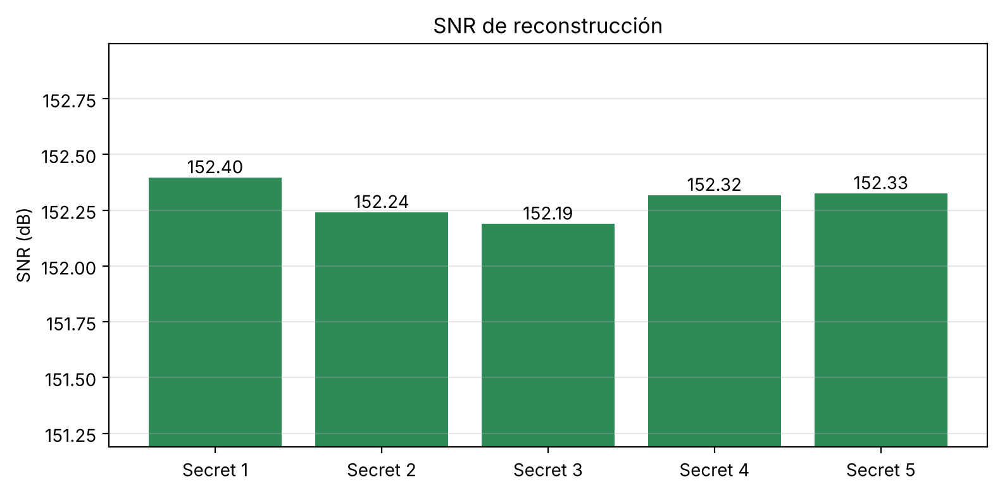

In [11]:
fig, eje = plt.subplots(figsize=(8, 4))
barras = eje.bar([r[0] for r in resultados], [r[1] for r in resultados], color=VERDE)
eje.bar_label(barras, fmt='%.2f')
eje.set_ylim(min(r[1] for r in resultados) - 1, max(r[1] for r in resultados) + 0.6)
eje.set_ylabel('SNR (dB)')
eje.set_title('SNR de reconstrucción')
eje.grid(alpha=0.3, axis='y')
fig.tight_layout()
fig.savefig(DIR_FIGURAS / 'metricas_snr.png', dpi=110)
plt.show()

In [12]:
def recuperar(encoded, K):
    X = rfft(encoded)
    X_rec = np.empty_like(X)
    X_rec[K] = X
    return irfft(X_rec, n=len(encoded))


print(f"{'Mensaje':10s} {'Sin guardar (dB)':>17s} {'float32 (dB)':>13s} {'int16 (dB)':>11s}")
for i in range(1, 6):
    _, x = leer_audio(DIR_ORIGINALES / f'secret{i}.wav')
    K = np.loadtxt(DIR_CLAVES / f'FFT_key_secret{i}.csv', skiprows=1, dtype=int)
    enc64 = irfft(rfft(x)[K], n=len(x))
    enc32 = enc64.astype(np.float32).astype(np.float64)
    pico = np.max(np.abs(enc64))
    enc16 = np.round(enc64 / pico * 32767) * pico / 32767
    snrs = [snr_db(x, recuperar(enc64, K)),
            snr_db(x, recuperar(enc32, K).astype(np.float32)),
            snr_db(x, recuperar(enc16, K).astype(np.float32))]
    print(f'Secret {i:<3d} {snrs[0]:17.1f} {snrs[1]:13.2f} {snrs[2]:11.2f}')

Mensaje     Sin guardar (dB)  float32 (dB)  int16 (dB)


Secret 1               302.8        152.40       88.20
Secret 2               302.8        152.24       88.48


Secret 3               302.8        152.19       88.01


Secret 4               302.8        152.32       87.86
Secret 5               302.7        152.33       88.39
